In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/piyalbaray111/fake-news/Fake.csv
/kaggle/input/datasets/piyalbaray111/true-news/True.csv


# **step : 01**

In [3]:

# Import pandas for loading and analyzing CSV datasets
import pandas as pd

# Import numpy for numerical operations
import numpy as np

# Import matplotlib for creating graphs and visualizations
import matplotlib.pyplot as plt

# Import seaborn for statistical data visualization
import seaborn as sns

# Display a success message after importing all required libraries
print("All required libraries imported successfully!")


All required libraries imported successfully!


# **Step 2: Upload and Load the Dataset**

In [4]:
# Load the fake news dataset into a pandas DataFrame
fake_df = pd.read_csv("/kaggle/input/datasets/piyalbaray111/fake-news/Fake.csv")
# Load the real news dataset into a pandas DataFrame
true_df = pd.read_csv("/kaggle/input/datasets/piyalbaray111/true-news/True.csv")



In [ ]:
fake_df.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [6]:
true_df.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [7]:
# Display the number of rows and columns in each dataset
print("Fake Dataset Shape:", fake_df.shape)
print("Real Dataset Shape:", true_df.shape)

Fake Dataset Shape: (23481, 4)
Real Dataset Shape: (21417, 4)


In [8]:
# Display the column names of both datasets
print("Fake Dataset Columns:", fake_df.columns.tolist())
print("Real Dataset Columns:", true_df.columns.tolist())

Fake Dataset Columns: ['title', 'text', 'subject', 'date']
Real Dataset Columns: ['title', 'text', 'subject', 'date']


# **Step 3: Basic Information ও Data Quality Check** 

In [9]:

# Display the structure and data types of the fake news dataset
print("Fake News Dataset Information:")
fake_df.info()




Fake News Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23481 entries, 0 to 23480
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    23481 non-null  object
 1   text     23481 non-null  object
 2   subject  23481 non-null  object
 3   date     23481 non-null  object
dtypes: object(4)
memory usage: 733.9+ KB


In [10]:
# Display the structure and data types of the real news dataset
print("\nReal News Dataset Information:")
true_df.info()


Real News Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21417 entries, 0 to 21416
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    21417 non-null  object
 1   text     21417 non-null  object
 2   subject  21417 non-null  object
 3   date     21417 non-null  object
dtypes: object(4)
memory usage: 669.4+ KB


In [11]:

# Count missing values in each column of the fake news dataset
print("Missing Values in Fake Dataset:")
print(fake_df.isnull().sum())




Missing Values in Fake Dataset:
title      0
text       0
subject    0
date       0
dtype: int64


In [12]:
# Count missing values in each column of the real news dataset
print("\nMissing Values in Real Dataset:")
print(true_df.isnull().sum())


Missing Values in Real Dataset:
title      0
text       0
subject    0
date       0
dtype: int64


In [13]:
# Count duplicate rows in the fake news dataset
print("Duplicate Rows in Fake Dataset:", fake_df.duplicated().sum())



Duplicate Rows in Fake Dataset: 3


In [14]:
# Count duplicate rows in the real news dataset
print("Duplicate Rows in Real Dataset:", true_df.duplicated().sum())

Duplicate Rows in Real Dataset: 206


In [15]:

# Display statistical information about the fake news dataset
print("Fake News Dataset Summary:")
display(fake_df.describe(include="all"))

# Display statistical information about the real news dataset
print("Real News Dataset Summary:")
display(true_df.describe(include="all"))


Fake News Dataset Summary:


,title,text,subject,date
count,23481,23481,23481,23481
unique,17903,17455,6,1681
top,MEDIA IGNORES Time That Bill Clinton FIRED His...,,News,"May 10, 2017"
freq,6,626,9050,46


Real News Dataset Summary:


,title,text,subject,date
count,21417,21417,21417,21417
unique,20826,21192,2,716
top,Factbox: Trump fills top jobs for his administ...,(Reuters) - Highlights for U.S. President Dona...,politicsNews,"December 20, 2017"
freq,14,8,11272,182


In [16]:

# Display statistical information about the fake news dataset
print("Fake News Dataset Summary:")
display(fake_df.describe(include="all"))



Fake News Dataset Summary:


,title,text,subject,date
count,23481,23481,23481,23481
unique,17903,17455,6,1681
top,MEDIA IGNORES Time That Bill Clinton FIRED His...,,News,"May 10, 2017"
freq,6,626,9050,46


In [17]:
# Display statistical information about the real news dataset
print("Real News Dataset Summary:")
display(true_df.describe(include="all"))


Real News Dataset Summary:


,title,text,subject,date
count,21417,21417,21417,21417
unique,20826,21192,2,716
top,Factbox: Trump fills top jobs for his administ...,(Reuters) - Highlights for U.S. President Dona...,politicsNews,"December 20, 2017"
freq,14,8,11272,182


# **# Step 4: Create Target Label for Binary Classification**

In [18]:

# Assign label 0 to all fake news articles
fake_df["label"] = 0



# Display the first five rows of the fake news dataset
print("Fake News Dataset:")
display(fake_df.head())




Fake News Dataset:


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0


In [19]:
# Assign label 1 to all real news articles
true_df["label"] = 1
# Display the first five rows of the real news dataset
print("Real News Dataset:")
display(true_df.head())

Real News Dataset:


,title,text,subject,date,label
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",1
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",1
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",1
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",1
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",1


In [20]:

# Count the number of articles in each target class
print("Fake News Label Distribution:")
print(fake_df["label"].value_counts())

print("Real News Label Distribution:")
print(true_df["label"].value_counts())

# Verify that each dataset contains the correct label
print("\nUnique Fake Dataset Labels:", fake_df["label"].unique())
print("Unique Real Dataset Labels:", true_df["label"].unique())


Fake News Label Distribution:
label
0    23481
Name: count, dtype: int64
Real News Label Distribution:
label
1    21417
Name: count, dtype: int64

Unique Fake Dataset Labels: [0]
Unique Real Dataset Labels: [1]


# **Step 5: Merge Both Datasets**

In [21]:

# Combine the fake and real news datasets into one DataFrame
df = pd.concat([fake_df, true_df], axis=0, ignore_index=True)

# Shuffle the combined dataset to mix fake and real news articles
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Display the first five rows of the combined dataset
print("Combined Dataset:")
display(df.head())


Combined Dataset:


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",1


In [22]:

# Display the total number of rows and columns
print("Combined Dataset Shape:", df.shape)




Combined Dataset Shape: (44898, 5)


In [23]:
# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())




Column Names:
['title', 'text', 'subject', 'date', 'label']


In [24]:
# Count the number of articles in each class
print("\nTarget Label Distribution:")
print(df["label"].value_counts())




Target Label Distribution:
label
0    23481
1    21417
Name: count, dtype: int64


In [25]:
# Display the dataset information
print("\nCombined Dataset Information:")
df.info()


Combined Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44898 non-null  object
 1   text     44898 non-null  object
 2   subject  44898 non-null  object
 3   date     44898 non-null  object
 4   label    44898 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 1.7+ MB


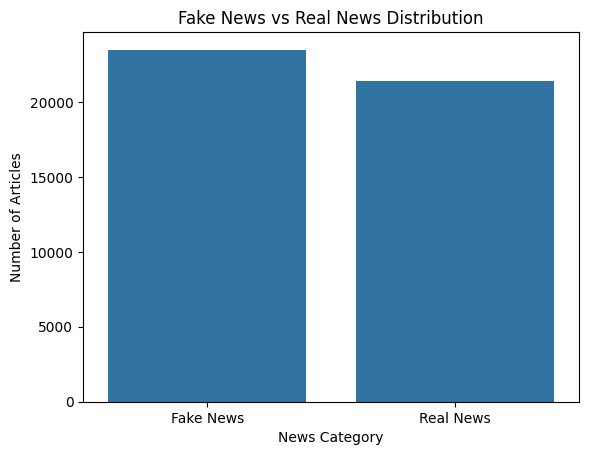

In [26]:

# Count the number of fake and real news articles
label_counts = df["label"].value_counts().sort_index()
# Create a bar chart to compare the two classes
sns.barplot(x=["Fake News", "Real News"], y=label_counts.values)

# Add a title and axis labels
plt.title("Fake News vs Real News Distribution")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")

# Display the chart
plt.show()



# **Step 6: Text Data Cleaning ও Preprocessing**

In [27]:

# Check missing values in the columns required for text classification
print("Missing values before cleaning:")
print(df[["title", "text", "label"]].isnull().sum())


Missing values before cleaning:
title    0
text     0
label    0
dtype: int64


In [28]:

# Remove rows where the title, text, or target label is missing
df = df.dropna(subset=["title", "text", "label"]).copy()

# Remove duplicate news articles based on their title and text
df = df.drop_duplicates(subset=["title", "text"]).reset_index(drop=True)

# Display the dataset shape after removing missing and duplicate rows
print("Dataset shape after cleaning:", df.shape)

# Verify that no required values are missing
print("\nMissing values after cleaning:")
print(df[["title", "text", "label"]].isnull().sum())


Dataset shape after cleaning: (39105, 5)

Missing values after cleaning:
title    0
text     0
label    0
dtype: int64


In [29]:


import re

# Check whether the required columns exist in the dataset
print("Available columns:", df.columns.tolist())

# Create the content column by combining the title and news text
df["content"] = (
    df["title"].fillna("").astype(str).str.strip()
    + " "
    + df["text"].fillna("").astype(str).str.strip()
)

# Define a function to clean news article text
def clean_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove URLs from the text
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove special characters while keeping letters and numbers
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove extra spaces between words
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Apply the cleaning function to the combined news content
df["cleaned_content"] = df["content"].apply(clean_text)

# Display sample rows to verify the result
display(df[["title", "text", "content", "cleaned_content", "label"]].head())

# Check the dataset shape and empty cleaned text values
print("Dataset Shape:", df.shape)
print("Empty Cleaned Text Rows:", (df["cleaned_content"] == "").sum())


Available columns: ['title', 'text', 'subject', 'date', 'label']


,title,text,content,cleaned_content,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",Ben Stein Calls Out 9th Circuit Court: Committ...,ben stein calls out 9th circuit court committe...,0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,Trump drops Steve Bannon from National Securit...,trump drops steve bannon from national securit...,1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,Puerto Rico expects U.S. to lift Jones Act shi...,puerto rico expects u s to lift jones act ship...,1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",OOPS: Trump Just Accidentally Confirmed He Lea...,oops trump just accidentally confirmed he leak...,0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",Donald Trump heads for Scotland to reopen a go...,donald trump heads for scotland to reopen a go...,1


Dataset Shape: (39105, 7)
Empty Cleaned Text Rows: 5


In [30]:
# Display the dataset dimensions after text preprocessing
print("Final Dataset Shape:", df.shape)

# Count the number of fake and real news articles after cleaning
print("\nClass Distribution:")
print(df["label"].value_counts())

# Check whether any cleaned text values are empty
print("\nEmpty cleaned text rows:", (df["cleaned_content"] == "").sum())


Final Dataset Shape: (39105, 7)

Class Distribution:
label
1    21197
0    17908
Name: count, dtype: int64

Empty cleaned text rows: 5


# **Step 7: Exploratory Data Analysis (EDA)**

In [31]:

# Display the dataset dimensions after preprocessing
print("Dataset Shape:", df.shape)

# Display the available columns
print("\nDataset Columns:")
print(df.columns.tolist())

# Display the number of articles in each class
print("\nClass Distribution:")
print(df["label"].value_counts())


Dataset Shape: (39105, 7)

Dataset Columns:
['title', 'text', 'subject', 'date', 'label', 'content', 'cleaned_content']

Class Distribution:
label
1    21197
0    17908
Name: count, dtype: int64


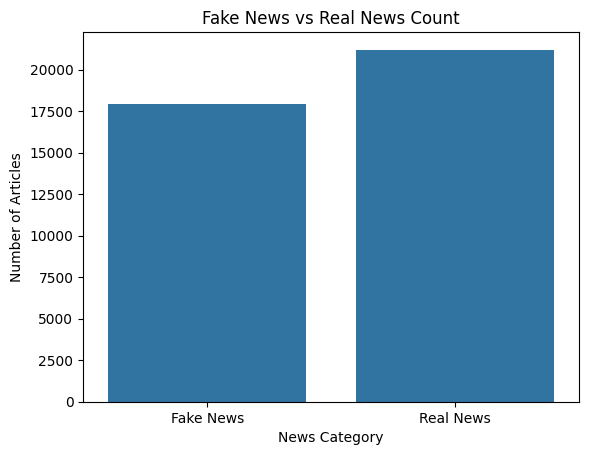

In [32]:

# Count the number of articles in each class
class_counts = df["label"].value_counts().sort_index()

# Create a bar chart to compare fake and real news counts
sns.barplot(x=["Fake News", "Real News"], y=class_counts.values)

# Add chart title and axis labels
plt.title("Fake News vs Real News Count")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")

# Display the chart
plt.show()


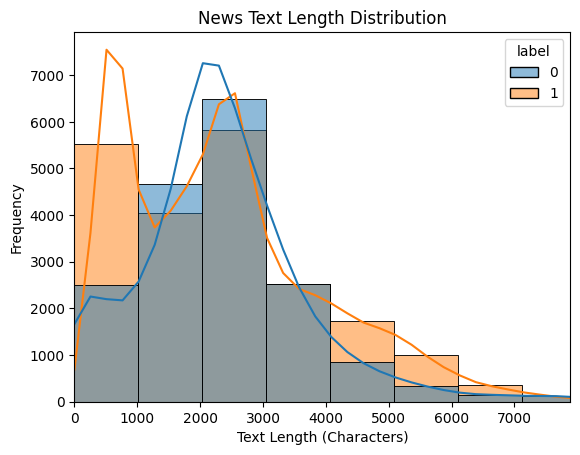

In [33]:

# Calculate the number of characters in each cleaned news article
df["text_length"] = df["cleaned_content"].str.len()

# Compare text length distributions for fake and real news
sns.histplot(
    data=df,
    x="text_length",
    hue="label",
    bins=50,
    kde=True
)

# Add chart title and axis labels
plt.title("News Text Length Distribution")
plt.xlabel("Text Length (Characters)")
plt.ylabel("Frequency")

# Limit the x-axis to improve readability if very long articles exist
plt.xlim(0, df["text_length"].quantile(0.99))

# Display the chart
plt.show()


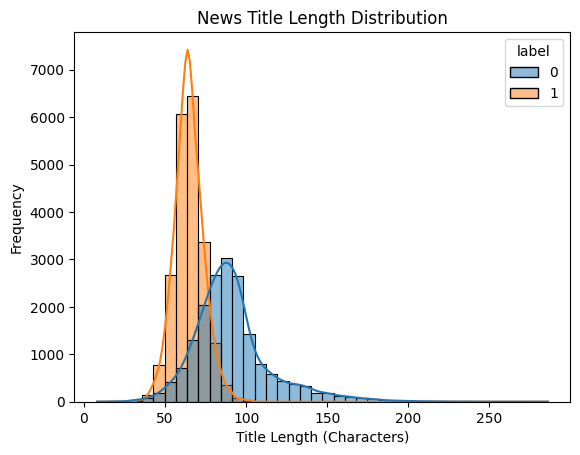

In [34]:
# Calculate the number of characters in each news title
df["title_length"] = df["title"].fillna("").astype(str).str.len()

# Compare title lengths between fake and real news
sns.histplot(
    data=df,
    x="title_length",
    hue="label",
    bins=40,
    kde=True
)

# Add chart title and axis labels
plt.title("News Title Length Distribution")
plt.xlabel("Title Length (Characters)")
plt.ylabel("Frequency")

# Display the chart
plt.show()

Average Text Length:
label
Fake News    2510.414061
Real News    2383.390008
Name: text_length, dtype: float64


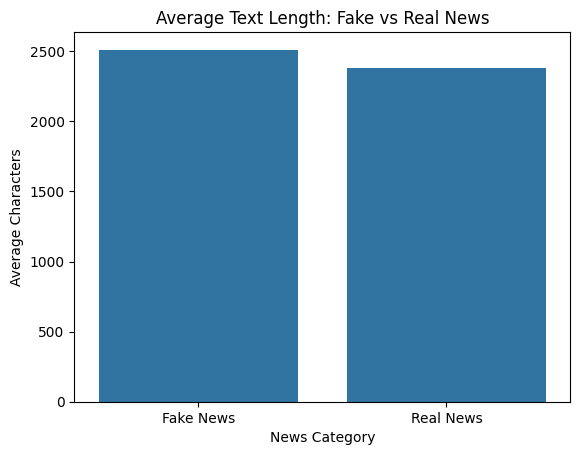

In [35]:

# Calculate the average article length for each class
average_length = df.groupby("label")["text_length"].mean()

# Display the average text length for fake and real news
print("Average Text Length:")
print(average_length.rename(index={0: "Fake News", 1: "Real News"}))

# Create a bar chart of average text length
sns.barplot(
    x=average_length.index.map({0: "Fake News", 1: "Real News"}),
    y=average_length.values
)

# Add chart title and axis labels
plt.title("Average Text Length: Fake vs Real News")
plt.xlabel("News Category")
plt.ylabel("Average Characters")

# Display the chart
plt.show()


# **# Step 8: Prepare Features (X) and Target (y)**

In [36]:

# Select the cleaned news text as the input feature
X = df["cleaned_content"]

# Select the label column as the target variable
y = df["label"]

# Display the shape of the input features and target variable
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

# Display a few examples of the input text
print("\nSample News Text:")
display(X.head())

# Display the corresponding target labels
print("\nSample Target Labels:")
display(y.head())


Features Shape: (39105,)
Target Shape: (39105,)

Sample News Text:


0    ben stein calls out 9th circuit court committe...
1    trump drops steve bannon from national securit...
2    puerto rico expects u s to lift jones act ship...
3    oops trump just accidentally confirmed he leak...
4    donald trump heads for scotland to reopen a go...
Name: cleaned_content, dtype: object


Sample Target Labels:


0    0
1    1
2    1
3    0
4    1
Name: label, dtype: int64

In [37]:

# Display the number of samples in each target class
print("Target Class Distribution:")
print(y.value_counts().sort_index())

# Display the unique target labels
print("\nUnique Target Labels:", sorted(y.unique()))

# Verify that the dataset contains exactly two classes
print("\nIs Binary Classification:", y.nunique() == 2)


Target Class Distribution:
label
0    17908
1    21197
Name: count, dtype: int64

Unique Target Labels: [np.int64(0), np.int64(1)]

Is Binary Classification: True


# **Step 9: Train-Test SplitStep **

In [38]:

# Import the function used to split data into training and testing sets
from sklearn.model_selection import train_test_split

# Split the text features and target labels into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,                  # Input news text
    y,                  # Target labels
    test_size=0.20,     # Reserve 20% of the data for testing
    random_state=42,    # Ensure reproducible results
    stratify=y          # Preserve the class proportions in both sets
)

# Display the number of samples in each set
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# Display the shapes of the training and testing sets
print("\nX_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)


Training Samples: 31284
Testing Samples: 7821

X_train Shape: (31284,)
X_test Shape: (7821,)
y_train Shape: (31284,)
y_test Shape: (7821,)


In [39]:

# Display the class distribution in the training set
print("Training Set Class Distribution:")
print(y_train.value_counts(normalize=True).sort_index())

# Display the class distribution in the testing set
print("\nTesting Set Class Distribution:")
print(y_test.value_counts(normalize=True).sort_index())


Training Set Class Distribution:
label
0    0.457934
1    0.542066
Name: proportion, dtype: float64

Testing Set Class Distribution:
label
0    0.457998
1    0.542002
Name: proportion, dtype: float64


# **Step 10: TF-IDF Vectorization**

In [40]:

# Import TfidfVectorizer to convert text into numerical features
from sklearn.feature_extraction.text import TfidfVectorizer

# Create a TF-IDF vectorizer with a maximum of 50,000 features
tfidf = TfidfVectorizer(
    max_features=50000,  # Limit the vocabulary size
    stop_words="english",  # Remove common English words
    ngram_range=(1, 2),  # Consider single words and pairs of words
    sublinear_tf=True  # Apply logarithmic scaling to term frequency
)

# Learn vocabulary and IDF weights from training text only
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing text using the learned training vocabulary
X_test_tfidf = tfidf.transform(X_test)

# Display the shapes of the transformed feature matrices
print("X_train TF-IDF Shape:", X_train_tfidf.shape)
print("X_test TF-IDF Shape:", X_test_tfidf.shape)


X_train TF-IDF Shape: (31284, 50000)
X_test TF-IDF Shape: (7821, 50000)


In [41]:

# Retrieve the feature names learned by the TF-IDF vectorizer
feature_names = tfidf.get_feature_names_out()

# Display the first 20 vocabulary terms
print("First 20 TF-IDF Features:")
print(feature_names[:20])

# Display the numerical representation of the first training article
print("\nFirst Training Article TF-IDF Vector:")
print(X_train_tfidf[0])

# Display the number of unique vocabulary features
print("\nTotal Vocabulary Features:", len(feature_names))


First 20 TF-IDF Features:
['00' '00 mark' '00 pm' '000' '000 000' '000 10' '000 according'
 '000 acres' '000 additional' '000 american' '000 americans' '000 barrels'
 '000 bond' '000 bpd' '000 cases' '000 children' '000 civilians'
 '000 clinton' '000 day' '000 emails']

First Training Article TF-IDF Vector:
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 459 stored elements and shape (1, 50000)>
  Coords	Values
  (0, 8079)	0.07973128509720781
  (0, 6954)	0.04700143922387074
  (0, 1733)	0.09176120716008176
  (0, 27830)	0.0375266830021437
  (0, 29953)	0.03297862936430308
  (0, 5296)	0.03607204217056523
  (0, 19535)	0.065674402310631
  (0, 26273)	0.03412610769581985
  (0, 37070)	0.05748245288441457
  (0, 19761)	0.15964574554684852
  (0, 10068)	0.13074063461284305
  (0, 47507)	0.028437360690923487
  (0, 15506)	0.019958431196565218
  (0, 24161)	0.020181842024365387
  (0, 34007)	0.04639187478018339
  (0, 24571)	0.02488196606223675
  (0, 11547)	0.06125882196858496
  (0, 17570)	0

# **Step 11: Compare 10 Binary Classification Algorithms**

In [42]:

# Import libraries for data preparation and model evaluation
import pandas as pd
import numpy as np
import time

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Import ten classification algorithms
from sklearn.linear_model import LogisticRegression, Perceptron, PassiveAggressiveClassifier
from sklearn.naive_bayes import BernoulliNB, ComplementNB, MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis

# Define the ten classification models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Perceptron": Perceptron(max_iter=1000, random_state=42),
    "Passive-Aggressive Classifier": PassiveAggressiveClassifier(max_iter=1000, random_state=42),
    "Linear Discriminant Analysis": LinearDiscriminantAnalysis(),
    "Quadratic Discriminant Analysis": QuadraticDiscriminantAnalysis(),
    "Bernoulli Naive Bayes": BernoulliNB(),
    "Complement Naive Bayes": ComplementNB(),
    "Multinomial Naive Bayes": MultinomialNB(),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Linear SVM": LinearSVC(random_state=42, max_iter=3000)
}

# Create containers to store evaluation results and trained models
results = []
trained_models = {}

# Define a function to train and evaluate one classification model
def evaluate_model(model, model_name):

    # Start timing the training and prediction process
    start_time = time.time()

    # Train the model using the TF-IDF training data
    model.fit(X_train_tfidf, y_train)

    # Predict labels for the TF-IDF test data
    y_pred = model.predict(X_test_tfidf)

    # Calculate classification evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    # Calculate the total time taken
    elapsed_time = time.time() - start_time

    # Save the successfully trained model for future use
    trained_models[model_name] = model

    # Return all evaluation metrics in a dictionary
    return {
        "Algorithm": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Time_Seconds": elapsed_time
    }

# Train and evaluate all ten models one by one
for model_name, model in models.items():

    # Handle errors so one failed model does not stop the comparison
    try:
        result = evaluate_model(model, model_name)
        results.append(result)

        # Print the evaluation metrics for the current model
        print("Algorithm:", model_name)
        print("Accuracy:", round(result["Accuracy"], 4))
        print("Precision:", round(result["Precision"], 4))
        print("Recall:", round(result["Recall"], 4))
        print("F1-Score:", round(result["F1-Score"], 4))
        print("Time (seconds):", round(result["Time_Seconds"], 2))
        print("-" * 50)

    except Exception as error:
        # Display the error and continue with the next algorithm
        print("Algorithm:", model_name)
        print("Error:", str(error)[:200])
        print("-" * 50)

# Create a comparison table from the successful model results
results_df = pd.DataFrame(results)

# Rank the models by F1-score, from highest to lowest
results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

# Display the final model comparison table
display(results_df)


Algorithm: Logistic Regression
Accuracy: 0.9899
Precision: 0.9864
Recall: 0.995
F1-Score: 0.9907
Time (seconds): 1.6
--------------------------------------------------
Algorithm: Perceptron
Accuracy: 0.9932
Precision: 0.995
Recall: 0.9925
F1-Score: 0.9937
Time (seconds): 0.21
--------------------------------------------------
Algorithm: Passive-Aggressive Classifier
Accuracy: 0.9959
Precision: 0.9948
Recall: 0.9976
F1-Score: 0.9962
Time (seconds): 0.32
--------------------------------------------------
Algorithm: Linear Discriminant Analysis
Error: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.
--------------------------------------------------
Algorithm: Quadratic Discriminant Analysis
Error: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.
--------------------------------------------------
Algorithm: Bernoulli Naive Bayes
Accuracy: 0.9757
Precision: 0.9805
Recal

,Algorithm,Accuracy,Precision,Recall,F1-Score,Time_Seconds
0,Passive-Aggressive Classifier,0.995908,0.994825,0.997641,0.996231,0.323604
1,Linear SVM,0.995653,0.994357,0.997641,0.995996,0.577892
2,Perceptron,0.993223,0.995033,0.992451,0.993740,0.209326
3,Logistic Regression,0.989899,0.986436,0.995046,0.990722,1.604513
4,Bernoulli Naive Bayes,0.975706,0.980536,0.974522,0.977520,0.111751
5,Multinomial Naive Bayes,0.957678,0.964574,0.957065,0.960805,0.062603
6,Complement Naive Bayes,0.957294,0.967441,0.953291,0.960314,0.063653
7,K-Nearest Neighbors,0.474108,1.000000,0.029724,0.057732,25.125147


# **Step 12: Confusion Matrix ও Classification Report**

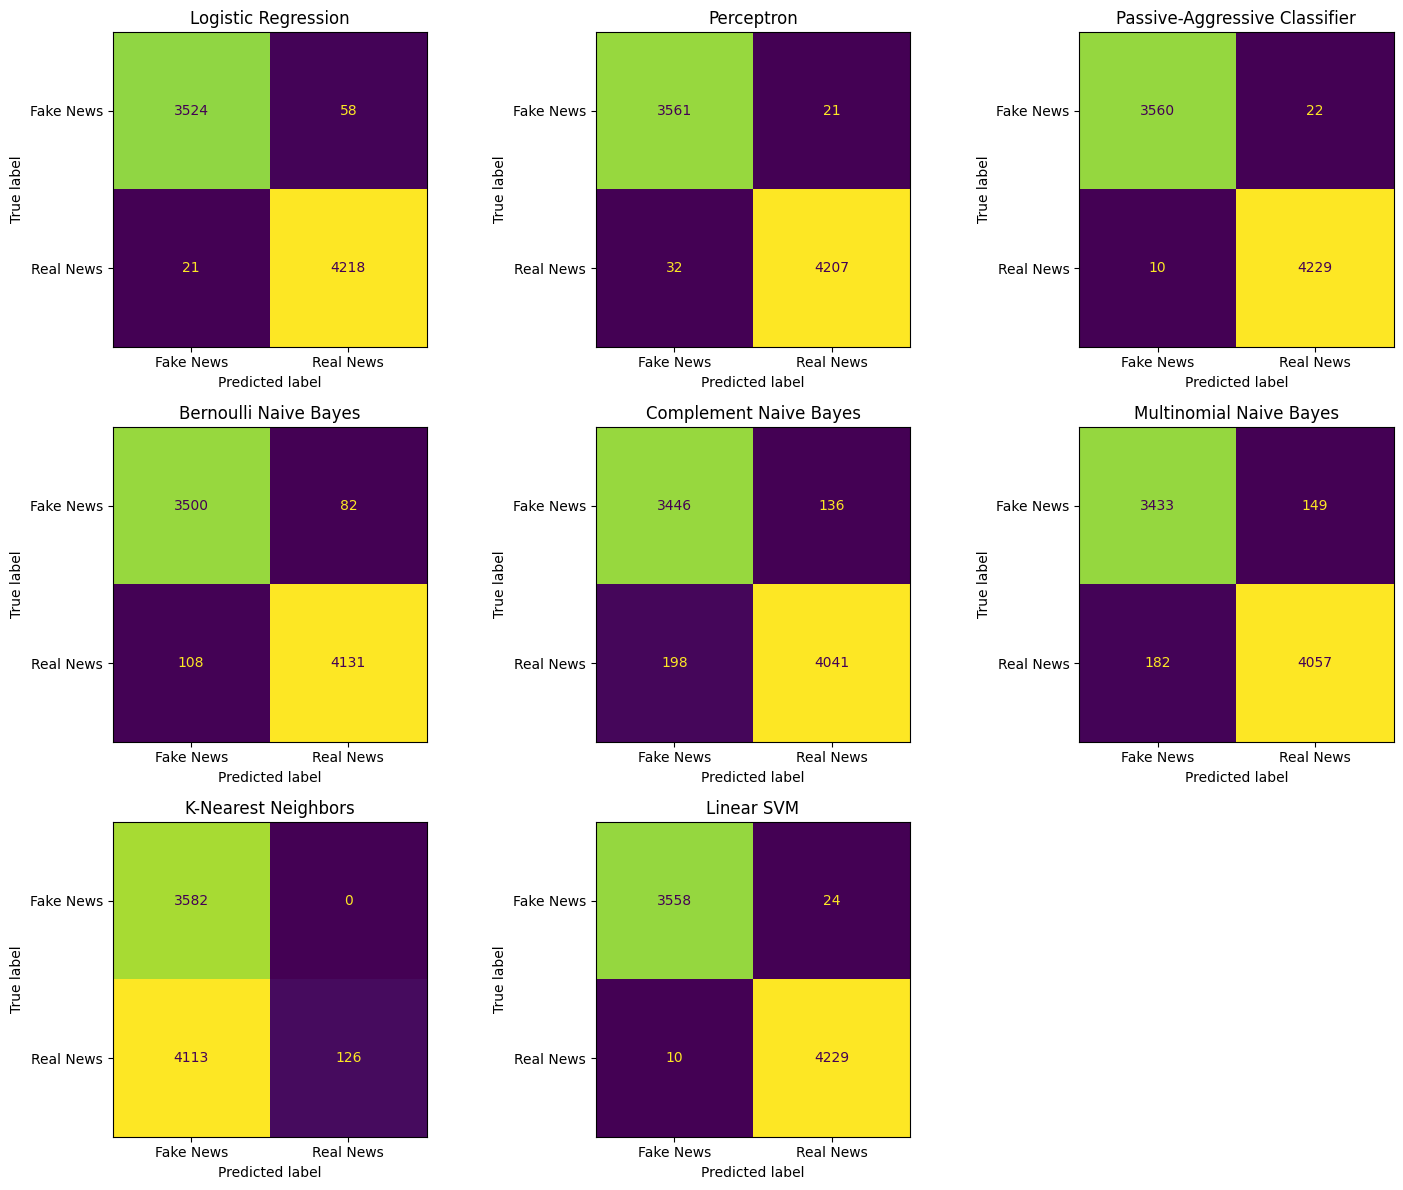

In [43]:

# Import libraries for confusion matrix visualization
import math
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Select the models that were trained successfully
successful_models = trained_models

# Calculate the subplot layout for all successful models
num_models = len(successful_models)
num_cols = 3
num_rows = math.ceil(num_models / num_cols)

# Create a grid to display confusion matrices
fig, axes = plt.subplots(
    num_rows,
    num_cols,
    figsize=(15, 4 * num_rows)
)

# Convert the axes into a one-dimensional array
axes = np.array(axes).reshape(-1)

# Generate a confusion matrix for every successful model
for index, (model_name, model) in enumerate(successful_models.items()):

    # Predict labels for the test dataset
    y_pred = model.predict(X_test_tfidf)

    # Display the confusion matrix for the current model
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=["Fake News", "Real News"],
        values_format="d",
        colorbar=False,
        ax=axes[index]
    )

    # Add the algorithm name to the plot
    axes[index].set_title(model_name)

# Hide any unused subplot spaces
for index in range(num_models, len(axes)):
    axes[index].set_visible(False)

# Adjust the layout and display all confusion matrices
plt.tight_layout()
plt.show()


# **Step 13: Final Model select and save**

In [47]:

# Import joblib to save the trained model and TF-IDF vectorizer
import joblib
import pandas as pd

# Select the best-performing Passive-Aggressive Classifier
best_model_name = "Passive-Aggressive Classifier"
best_model = trained_models[best_model_name]

# Display the evaluation results of the selected model
best_result = results_df[
    results_df["Algorithm"] == best_model_name
]

print("Selected Model:", best_model_name)
display(best_result)

# Save the trained classification model to a file
joblib.dump(best_model, "passive_aggressive_model.pkl")

# Save the fitted TF-IDF vectorizer to a separate file
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

# Confirm the saved filenames
print("Model saved as: passive_aggressive_model.pkl")
print("Vectorizer saved as: tfidf_vectorizer.pkl")


Selected Model: Passive-Aggressive Classifier


,Algorithm,Accuracy,Precision,Recall,F1-Score,Time_Seconds
0,Passive-Aggressive Classifier,0.995908,0.994825,0.997641,0.996231,0.323604


Model saved as: passive_aggressive_model.pkl
Vectorizer saved as: tfidf_vectorizer.pkl


In [52]:
# Replace this example with the news article you want to test
news = """
Paste your news headline and full article text here.
"""

# Predict whether the provided news is fake or real
predict_news(news)


Prediction: FAKE NEWS


Model: Passive-Aggressive Classifier
Accuracy:   99.59 %
Precision:  99.48 %
Recall:     99.76 %
F1-Score:   99.62 %

Classification Report:
              precision    recall  f1-score   support

   Fake News       1.00      0.99      1.00      3582
   Real News       0.99      1.00      1.00      4239

    accuracy                           1.00      7821
   macro avg       1.00      1.00      1.00      7821
weighted avg       1.00      1.00      1.00      7821



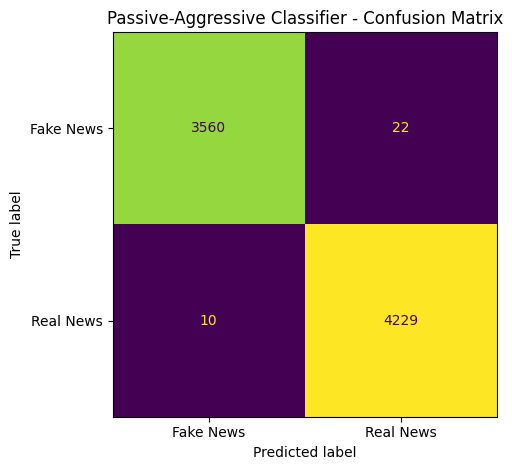

In [53]:

# Import libraries for final model evaluation
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Generate predictions using the selected Passive-Aggressive model
y_pred = best_model.predict(X_test_tfidf)

# Calculate the final classification metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

# Print the final evaluation scores as percentages
print("Model: Passive-Aggressive Classifier")
print("Accuracy:  ", round(accuracy * 100, 2), "%")
print("Precision: ", round(precision * 100, 2), "%")
print("Recall:    ", round(recall * 100, 2), "%")
print("F1-Score:  ", round(f1 * 100, 2), "%")

# Display the detailed classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Fake News", "Real News"],
        zero_division=0
    )
)

# Plot the confusion matrix for the selected model
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Fake News", "Real News"],
    values_format="d",
    colorbar=False
)

# Add a title and display the confusion matrix
plt.title("Passive-Aggressive Classifier - Confusion Matrix")
plt.tight_layout()
plt.show()


In [55]:

# Import Gradio to create the web application
import gradio as gr

# Define a function to classify news using the trained model
def predict_news_app(news_text):

    # Validate the user input
    if not news_text or not news_text.strip():
        return " Please enter a news headline or article."

    # Convert the input news text into TF-IDF features
    news_tfidf = tfidf.transform([news_text])

    # Predict the news category using the trained Passive-Aggressive model
    prediction = best_model.predict(news_tfidf)[0]

    # Return the prediction result
    if prediction == 0:
        return " FAKE NEWS"

    return " REAL NEWS"


# Define custom CSS for the navbar, sections, and buttons
custom_css = """
.navbar {
    background: #166534;
    padding: 16px 24px;
    border-radius: 12px;
    color: white;
    text-align: center;
}
.navbar h1 {
    color: white;
    margin: 0;
}
.section-box {
    border-radius: 12px;
    padding: 18px;
}
#predict-button {
    background: #15803d;
    color: white;
}
"""

# Build the complete Fake News Detection interface
with gr.Blocks(
    css=custom_css,
    title="Fake News Detection | NewsGuard"
) as demo:

    # Create the green navigation header
    gr.HTML("""
    <div class="navbar">
        <h1> NewsGuard AI</h1>
        <p>Fake News Detection System</p>
        <p>Home &nbsp; | &nbsp; About &nbsp; | &nbsp; Contact</p>
    </div>
    """)

    # Create the Home section
    with gr.Column(elem_classes="section-box"):
        gr.Markdown("""
        ##  Home

        Welcome to **NewsGuard AI**, a Machine Learning-based
        Fake News Detection system.

        Enter a news headline or the full article below to get a
        prediction from our trained Passive-Aggressive Classifier.
        """)

        # Add the news input box
        news_input = gr.Textbox(
            lines=8,
            label="Enter News",
            placeholder="Paste your news headline or full article here..."
        )

        # Add the prediction and clear buttons
        with gr.Row():
            predict_button = gr.Button(
                " Predict News",
                variant="primary",
                elem_id="predict-button"
            )
            clear_button = gr.ClearButton(
                components=[news_input],
                value="🧹 Clear"
            )

        # Display the prediction result
        prediction_output = gr.Textbox(
            label="Prediction Result",
            lines=2,
            interactive=False
        )

        # Connect the Predict button to the prediction function
        predict_button.click(
            fn=predict_news_app,
            inputs=news_input,
            outputs=prediction_output
        )

    # Create the About section with project details
    with gr.Column(elem_classes="section-box"):
        gr.Markdown("""
        ##  About This Project

        **NewsGuard AI** is a Binary Text Classification project
        designed to classify news articles into two categories:
        Fake News and Real News.

        ### Project Objectives
        - Analyze news text using Natural Language Processing (NLP).
        - Identify patterns that help distinguish fake and real news.
        - Apply Machine Learning to classify previously unseen text.
        - Provide a simple interface for users to test news articles.

        ###  Technologies Used
        - **Python:** Core programming language.
        - **Pandas and NumPy:** Data preparation and manipulation.
        - **Scikit-learn:** Machine Learning and model evaluation.
        - **TF-IDF Vectorizer:** Converts text into numerical features.
        - **Passive-Aggressive Classifier:** Selected classification model.
        - **Gradio:** Creates the interactive web interface.

        ###  Project Workflow
        1. Load the Fake News and Real News datasets.
        2. Inspect and clean the data.
        3. Assign binary labels to the news articles.
        4. Split the data into training and testing sets.
        5. Convert text into TF-IDF features.
        6. Compare classification algorithms using evaluation metrics.
        7. Select the Passive-Aggressive Classifier based on the
           project's evaluation results.
        8. Predict the category of user-provided news text.

        ###  Evaluation Metrics
        Accuracy, Precision, Recall, F1-Score, and Confusion Matrix.

        ###  Important Note
        This application provides a machine learning prediction,
        not a guaranteed fact-check. Always verify important news
        using reliable sources.
        """)

    # Create the Contact section
    with gr.Column(elem_classes="section-box"):
        gr.Markdown("""
        ##  Contact

        For questions, feedback, or project-related discussions,
        contact the developer using the email address below.

        **Email:** [piyalbaray314@gmail.com](mailto:piyalbaray314@gmail.com)
        """)

    # Add a footer to the application
    gr.Markdown("""
    ---
    <center> NewsGuard AI | Fake News Detection Project</center>
    """)


# Launch the app and generate a temporary public link
demo.launch(share=True)


/tmp/ipykernel_48/3284222407.py:48: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: css. Please pass these parameters to launch() instead.
  with gr.Blocks(


* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://659f373bcc3aa6835e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
